# Laporan Klasifikasi Tutupan Lahan Jawa Timur

## Ringkasan laporan

Laporan ini mendokumentasikan pemetaan lima kelas tutupan lahan dari fitur spektral Sentinel-2 menggunakan Random Forest. Analisis mencakup audit data, pembagian data berbasis poligon, evaluasi model, analisis kepentingan fitur, dan eksplorasi peta.

| Model | Accuracy | Balanced accuracy | Macro F1 | Weighted F1 | F1 `farm land` |
|---|---:|---:|---:|---:|---:|
| Random Forest baseline (model peta) | 0,9309 | 0,8864 | 0,8852 | 0,9305 | 0,6808 |
| Random Forest `class_weight=balanced` | 0,9272 | 0,8998 | 0,8774 | 0,9284 | sekitar 0,6570 |

Baseline dipilih untuk menghasilkan peta karena unggul pada accuracy, macro F1, weighted F1, dan F1 `farm land`; model balanced memiliki balanced accuracy lebih tinggi. Tidak ada model yang terbaik pada seluruh metrik. Angka ini berasal dari **sampel uji yang dipisahkan menurut poligon**, bukan estimasi akurasi independen seluruh piksel raster.

**Cakupan dan kehati-hatian.** Raster beresolusi 20 m meliputi cakupan Sentinel-2 yang mencakup laut serta wilayah di luar batas administratif Jawa Timur. Luas atau proporsi kelas pada raster bukan statistik resmi provinsi. Tanggal akuisisi dan metadata produk Sentinel-2 belum tersedia pada artefak proyek.

Ikuti urutan bagian untuk meninjau pemahaman data, prapemrosesan, pemodelan, evaluasi, dan peta interaktif. Cell kode menampilkan pemeriksaan yang digunakan; sebagian cell memerlukan data lokal dan tidak perlu dijalankan ulang untuk membaca hasil tersimpan.


# 1. Pemahaman Data dan Wilayah Studi

## 1.1 Latar Belakang

Informasi tutupan lahan memiliki peran penting dalam memahami karakteristik permukaan bumi, mendukung pemantauan lingkungan, serta menyediakan informasi spasial untuk perencanaan wilayah. Perubahan tutupan lahan dapat memengaruhi keseimbangan ekosistem, ketersediaan sumber daya air, dan perkembangan kawasan terbangun.

Citra satelit Sentinel-2 menyediakan informasi spektral yang dapat dimanfaatkan untuk membedakan berbagai objek di permukaan bumi. Setiap jenis tutupan lahan memiliki karakteristik pantulan elektromagnetik yang berbeda. Karakteristik tersebut dapat dianalisis melalui kombinasi band spektral dan indeks spektral untuk membantu proses klasifikasi.

Pada proyek ini, algoritma Random Forest digunakan untuk mengklasifikasikan citra Sentinel-2 ke dalam lima kelas tutupan lahan, yaitu kawasan terbangun (*built-up area*), lahan pertanian (*farmland*), hutan (*forest*), mangrove, dan badan air (*water body*). Model dibangun menggunakan sampel berlabel yang direpresentasikan melalui fitur spektral, kemudian diterapkan pada citra raster untuk menghasilkan peta klasifikasi.

Penelitian ini juga mengevaluasi performa model menggunakan pembagian data berbasis poligon serta membandingkan model baseline dengan model yang menerapkan penanganan ketidakseimbangan kelas. Dengan demikian, analisis tidak hanya berfokus pada nilai akurasi keseluruhan, tetapi juga pada kemampuan model mengenali setiap kelas tutupan lahan.

## 1.2 Tujuan Analisis

Tujuan proyek ini adalah:

1. Mengolah citra Sentinel-2 menjadi data raster yang siap digunakan untuk klasifikasi.
2. Mengekstraksi fitur spektral dari band asli dan indeks spektral.
3. Membangun model klasifikasi tutupan lahan menggunakan algoritma Random Forest.
4. Mengevaluasi performa model menggunakan metrik klasifikasi dan pengujian berbasis poligon.
5. Menghasilkan peta klasifikasi serta menyajikannya melalui visualisasi geospasial interaktif.
6. Menganalisis keterbatasan model, khususnya pada kelas dengan jumlah sampel yang tidak seimbang.

## 1.3 Wilayah Studi

Wilayah analisis menggunakan cakupan spasial mosaik citra Sentinel-2 yang tersedia dalam proyek. Cakupan raster meliputi sebagian wilayah Jawa Timur dan area sekitarnya, sehingga tidak seluruh piksel hasil klasifikasi dapat langsung dianggap mewakili wilayah administratif Provinsi Jawa Timur.

Analisis dilakukan pada raster dengan sistem koordinat UTM zona 49S (EPSG:32749) dan resolusi spasial 20 meter. Setiap piksel merepresentasikan area nominal 400 m² di permukaan bumi.

## 1.4 Business Understanding dan Tujuan

Tujuan bisnis/analisis adalah menyediakan informasi awal sebaran tutupan lahan untuk membantu pemantauan perubahan lingkungan dan diskusi perencanaan wilayah Jawa Timur. Produk ini adalah peta tematik hasil model, bukan peta legal atau pengganti survei lapangan. Peta digunakan untuk menjawab lokasi kelas terbangun, pertanian, hutan, mangrove, dan perairan yang terindikasi pada citra.

Rujukan nomenklatur penutup lahan Indonesia yang dapat digunakan dalam penyesuaian kelas adalah SNI 7645-1:2014. Lima label proyek merupakan agregasi operasional untuk tugas ini, bukan pemetaan satu-ke-satu seluruh kelas/kode resmi SNI. `water body` menggabungkan perairan terbuka dan perairan darat karena data referensi saat ini hanya menyediakan satu kelas tersebut.

## 1.5 Pengumpulan dan Pemahaman Data

Data citra yang benar-benar digunakan adalah mosaik Sentinel-2 lokal pada `data/mosaic/*_20m_mosaic.tif`, bukan layanan citra basemap web. Poligon referensi hasil digitasi disimpan sebagai lima GeoJSON di `labels_clean/`, lalu fitur piksel diekstrak ke `data/processed/training_samples.csv`. Tanggal akuisisi dan metadata produk sumber tidak tercatat pada artefak proyek yang diperiksa; karena itu periode citra perlu dilengkapi dari metadata sumber sebelum laporan ilmiah final.

Data latih berisi 49.062 sampel dari 395 poligon: forest 23.767, build-up 12.235, water body 7.146, farm land 3.589, dan mangrove 2.325. Pembagian `GroupShuffleSplit` 75:25 dilakukan berdasarkan poligon, sehingga satu poligon tidak muncul di train dan test: train 37.078 sampel (296 poligon), test 11.984 sampel (99 poligon), overlap 0. Distribusi test: build-up 3.977; farm land 362; forest 4.946; mangrove 1.025; water body 1.674.

### Band Sentinel-2 MSI

Band yang tersedia dalam fitur model diselaraskan ke grid 20 m. Band lain yang tidak masuk fitur tetap dijelaskan untuk konteks instrumen.

| Band | Rentang tengah (nm, kira-kira) | Resolusi asli | Peran utama |
|---|---:|---:|---|
| B01 | 443 | 60 m | Aerosol pesisir |
| B02 | 490 | 10 m | Biru; komposit warna alami |
| B03 | 560 | 10 m | Hijau; komposit warna alami dan MNDWI |
| B04 | 665 | 10 m | Merah; vegetasi dan komposit warna alami |
| B05 | 705 | 20 m | Red-edge; kondisi vegetasi |
| B06 | 740 | 20 m | Red-edge; struktur/kondisi vegetasi |
| B07 | 783 | 20 m | Red-edge; vegetasi |
| B08 | 842 | 10 m | NIR; vegetasi, NDVI, NDMI |
| B8A | 865 | 20 m | Narrow NIR; vegetasi dan pemisahan mangrove/hutan |
| B09 | 945 | 60 m | Uap air atmosfer |
| B10 | 1.375 | 60 m | Cirrus/awan tipis |
| B11 | 1.610 | 20 m | SWIR; kelembapan dan air |
| B12 | 2.190 | 20 m | SWIR; kelembapan/struktur vegetasi |

Model memakai 10 band: B02, B03, B04, B05, B06, B07, B08, B8A, B11, B12 (nilai reflektansi diskalakan 10.000 pada pemodelan). Untuk membedakan mangrove dan hutan, B8A/B11/B12 memberi informasi NIR-SWIR tambahan; pemisahan tetap harus didukung sampel berlabel yang representatif. B02/B03/B04 ditampilkan sebagai komposit warna alami RGB.

### Fitur Turunan dan Rumus

Total fitur model 14: sepuluh band di atas dan empat indeks. NDVI = (B08 − B04) / (B08 + B04), untuk kehijauan vegetasi; NDMI = (B08 − B11) / (B08 + B11), untuk kandungan kelembapan vegetasi; MNDWI = (B03 − B11) / (B03 + B11), untuk menonjolkan air; NDBI = (B11 − B08) / (B11 + B08), untuk kawasan terbangun. Indeks dihitung hanya jika penyebut tidak nol; nilai tidak valid dikeluarkan dari mask pelatihan.

### Kelas Operasional dan Hasil Eksperimen

| Kelas peta | Makna operasional |
|---|---|
| Build-up | Kawasan/bangunan terbangun |
| Farm land | Lahan pertanian, termasuk sawah sesuai label yang tersedia |
| Forest | Tutupan hutan non-mangrove |
| Mangrove | Tutupan mangrove pesisir |
| Water body | Gabungan laut, danau/ranu, sungai, dan perairan terbuka; belum dipisah karena tidak ada label berbeda |

Pada perbandingan eksperimen yang tersimpan, SVM RBF memperoleh accuracy tertinggi 93,94% (macro-F1 0,8850), dibanding Random Forest 92,72% (macro-F1 0,8774) dan Gradient Boosting 91,37% (macro-F1 0,8572). Raster peta yang saat ini dipakai Streamlit/notebook masih dibuat dengan Random Forest baseline; angka pembanding SVM tidak boleh dianggap sebagai metrik raster RF. Validasi final Random Forest baseline pada split berbasis poligon menghasilkan accuracy 93,09%, macro-F1 0,8852; kelas farm land memiliki F1 0,6808 sehingga perlu tambahan digitasi sawah dan validasi lapangan.

## 1.6 Tampilan Peta dan Batasan

Peta Leaflet/Folium memakai citra Sentinel-2 B04/B03/B02 sebagai basemap lokal; lima checkbox klasifikasi dan lima layer sampel dapat dinyalakan sendiri-sendiri. Mematikan semua kelas menyisakan citra Sentinel. Esri World Imagery dan OpenStreetMap disediakan sebagai basemap alternatif, bukan citra Sentinel. Raster yang ada hanya mencakup sebagian Jawa Timur dan area sekitar; memilih cakupan Pulau Jawa/Indonesia tidak memperluas area prediksi. Hasil sensitif terhadap awan, tanggal citra, ketidakseimbangan label, dan akurasi digitasi.


In [1]:

from pathlib import Path
import pandas as pd

# Direktori utama proyek
_search_roots = (Path.cwd(), *Path.cwd().parents)
_project_candidates = (
    *_search_roots,
    *(parent / "pemrosesan-data-sains" / "klasifikasi-tutupan-lahan" for parent in _search_roots),
)
PROJECT_DIR = next(
    (p for p in _project_candidates if (p / "laporan_klasifikasi.ipynb").is_file() and (p / "data").is_dir()),
    Path.cwd(),
)
import sys
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

print("Direktori proyek:", PROJECT_DIR)
print("\nPemeriksaan data utama")

paths_to_check = {
    "Data sampel": PROJECT_DIR / "data" / "processed" / "training_samples.csv",
    "Mosaik citra": PROJECT_DIR / "data" / "mosaic",
    "Label referensi": PROJECT_DIR / "labels_clean",
    "Hasil klasifikasi": PROJECT_DIR / "results" / "classification",
    "Laporan eksperimen": PROJECT_DIR / "results" / "laporan_final",
}

status = []

for name, path in paths_to_check.items():
    status.append({
        "Komponen": name,
        "Status": "Tersedia" if path.exists() else "Tidak ditemukan",
        "Lokasi": str(path)
    })

status_df = pd.DataFrame(status)
display(status_df)

Direktori proyek: d:\psd file\klasifikasi-tutupan-lahan

Pemeriksaan data utama


,Komponen,Status,Lokasi
0,Data sampel,Tersedia,d:\psd file\klasifikasi-tutupan-lahan\data\pro...
1,Mosaik citra,Tersedia,d:\psd file\klasifikasi-tutupan-lahan\data\mosaic
2,Label referensi,Tersedia,d:\psd file\klasifikasi-tutupan-lahan\labels_c...
3,Hasil klasifikasi,Tersedia,d:\psd file\klasifikasi-tutupan-lahan\results\...
4,Laporan eksperimen,Tersedia,d:\psd file\klasifikasi-tutupan-lahan\results\...


Jumlah seluruh sampel: 49,062
Jumlah fitur/kolom: 16

Distribusi sampel per kelas:


,Kelas,Jumlah Sampel,Persentase (%)
0,forest,23767,48.44
1,build_up,12235,24.94
2,water body,7146,14.57
3,farm land,3589,7.32
4,mangrove,2325,4.74


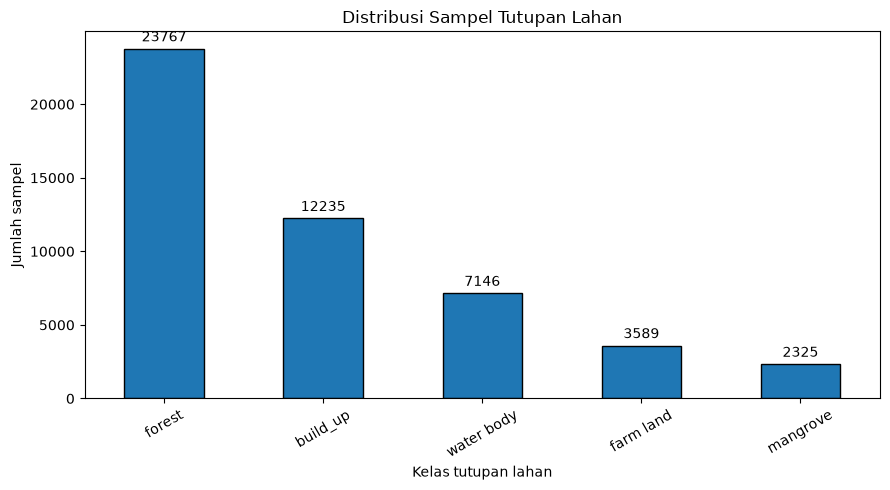

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

sample_file = PROJECT_DIR / "data" / "processed" / "training_samples.csv"
df = pd.read_csv(sample_file)

# Ringkasan jumlah sampel per kelas
class_counts = (
    df["label"]
    .value_counts()
    .rename_axis("Kelas")
    .reset_index(name="Jumlah Sampel")
)

class_counts["Persentase (%)"] = (
    class_counts["Jumlah Sampel"] / len(df) * 100
).round(2)

print(f"Jumlah seluruh sampel: {len(df):,}")
print(f"Jumlah fitur/kolom: {len(df.columns)}")
print("\nDistribusi sampel per kelas:")
display(class_counts)

# Grafik distribusi sampel
fig, ax = plt.subplots(figsize=(9, 5))

class_counts.plot(
    x="Kelas",
    y="Jumlah Sampel",
    kind="bar",
    ax=ax,
    legend=False,
    edgecolor="black"
)

ax.set_title("Distribusi Sampel Tutupan Lahan")
ax.set_xlabel("Kelas tutupan lahan")
ax.set_ylabel("Jumlah sampel")
ax.tick_params(axis="x", rotation=30)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

### 1.5 Pemeriksaan fitur


In [3]:

# Memeriksa struktur fitur pada data sampel

expected_features = [
    "B02", "B03", "B04", "B05", "B06",
    "B07", "B08", "B8A", "B11", "B12",
    "NDVI", "NDMI", "MNDWI", "NDBI"
]

print("Ukuran dataset:", df.shape)
print("\nDaftar kolom:")
print(df.columns.tolist())

missing_features = [
    feature for feature in expected_features
    if feature not in df.columns
]

if missing_features:
    print("\nFitur yang belum ditemukan:", missing_features)
else:
    print("\nSemua 14 fitur yang diharapkan tersedia.")

print("\nInformasi tipe data:")
display(df[expected_features].dtypes.rename("Tipe Data").to_frame())

print("\nStatistik deskriptif fitur:")
display(df[expected_features].describe().T.round(4))

Ukuran dataset: (49062, 16)

Daftar kolom:
['B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B11', 'B12', 'NDVI', 'NDMI', 'MNDWI', 'NDBI', 'label', 'polygon_id']

Semua 14 fitur yang diharapkan tersedia.

Informasi tipe data:


,Tipe Data
B02,float64
B03,float64
B04,float64
B05,float64
B06,float64
B07,float64
B08,float64
B8A,float64
B11,float64
B12,float64



Statistik deskriptif fitur:


,count,mean,std,min,25%,50%,75%,max
B02,49062.0,0.1628,0.0387,0.0741,0.1369,0.1558,0.1803,0.8411
B03,49062.0,0.1903,0.0380,0.1071,0.1640,0.1834,0.2104,0.7801
B04,49062.0,0.1928,0.0530,0.0940,0.1500,0.1836,0.2288,0.8279
B05,49062.0,0.2476,0.0445,0.1088,0.2181,0.2451,0.2752,0.7373
B06,49062.0,0.3260,0.0709,0.0918,0.2981,0.3304,0.3678,0.7366
B07,49062.0,0.3629,0.0867,0.0938,0.3243,0.3665,0.4178,0.7533
B08,49062.0,0.3722,0.0963,0.0711,0.3286,0.3783,0.4341,0.8814
B8A,49062.0,0.3935,0.1022,0.0822,0.3472,0.4019,0.4611,0.7804
B11,49062.0,0.3605,0.0954,0.1009,0.3239,0.3775,0.4223,0.7679
B12,49062.0,0.2801,0.0867,0.1002,0.2206,0.2812,0.3450,1.0577


### 1.6 Pemeriksaan kualitas data


In [4]:

# Pemeriksaan kualitas data sampel

print("=== PEMERIKSAAN KUALITAS DATA ===")
print(f"Jumlah baris       : {len(df):,}")
print(f"Jumlah kolom       : {len(df.columns)}")
print(f"Duplikat seluruh baris: {df.duplicated().sum():,}")
print(f"Nilai kosong       : {df.isna().sum().sum():,}")

# Memeriksa nilai tak hingga pada fitur
import numpy as np

feature_data = df[expected_features].apply(pd.to_numeric, errors="coerce")

quality_summary = pd.DataFrame({
    "Nilai kosong": feature_data.isna().sum(),
    "Nilai tak hingga": np.isinf(feature_data).sum(),
    "Nilai unik": feature_data.nunique()
})

display(quality_summary)

# Memeriksa jumlah sampel per kelas
print("\nJumlah sampel per kelas:")
display(df["label"].value_counts().rename("Jumlah Sampel").to_frame())

=== PEMERIKSAAN KUALITAS DATA ===
Jumlah baris       : 49,062
Jumlah kolom       : 16
Duplikat seluruh baris: 0
Nilai kosong       : 0


,Nilai kosong,Nilai tak hingga,Nilai unik
B02,0,0,2375
B03,0,0,2319
B04,0,0,2734
B05,0,0,2691
B06,0,0,3833
B07,0,0,4507
B08,0,0,4837
B8A,0,0,4983
B11,0,0,4569
B12,0,0,3884



Jumlah sampel per kelas:


,Jumlah Sampel
label,
forest,23767
build_up,12235
water body,7146
farm land,3589
mangrove,2325


# 2. Pengumpulan dan Prapemrosesan Data

Tahap ini memeriksa mosaik Sentinel-2, sistem grid, fitur turunan, dan sampel berlabel yang digunakan untuk membangun model. Nilai keluaran ditafsirkan dengan mempertimbangkan mask kualitas, resolusi, dan keterbatasan metadata akuisisi.


In [5]:

from pathlib import Path
import rasterio
import pandas as pd
from IPython.display import display

mosaic_dir = PROJECT_DIR / "data" / "mosaic"

raster_files = sorted(mosaic_dir.glob("*.tif"))

raster_summary = []

for file in raster_files:
    try:
        with rasterio.open(file) as src:
            raster_summary.append({
                "Nama file": file.name,
                "Band": src.count,
                "Lebar piksel": src.width,
                "Tinggi piksel": src.height,
                "Resolusi X (m)": src.res[0],
                "Resolusi Y (m)": abs(src.res[1]),
                "CRS": str(src.crs),
                "Tipe data": src.dtypes[0]
            })
    except Exception as error:
        print(f"Gagal membaca {file.name}: {error}")

if raster_summary:
    display(pd.DataFrame(raster_summary))
else:
    print("Tidak ditemukan file GeoTIFF langsung di folder data/mosaic.")

,Nama file,Band,Lebar piksel,Tinggi piksel,Resolusi X (m),Resolusi Y (m),CRS,Tipe data
0,B02_20m.tif,1,5490,5490,20.0,20.0,EPSG:32749,uint16
1,B02_20m_mosaic.tif,1,20490,10491,20.0,20.0,EPSG:32749,uint16
2,B03_20m.tif,1,5490,5490,20.0,20.0,EPSG:32749,uint16
3,B03_20m_mosaic.tif,1,20490,10491,20.0,20.0,EPSG:32749,uint16
4,B04_20m.tif,1,5490,5490,20.0,20.0,EPSG:32749,uint16
5,B04_20m_mosaic.tif,1,20490,10491,20.0,20.0,EPSG:32749,uint16
6,B05_20m.tif,1,5490,5490,20.0,20.0,EPSG:32749,uint16
7,B05_20m_mosaic.tif,1,20490,10491,20.0,20.0,EPSG:32749,uint16
8,B06_20m.tif,1,5490,5490,20.0,20.0,EPSG:32749,uint16
9,B06_20m_mosaic.tif,1,20490,10491,20.0,20.0,EPSG:32749,uint16


## 2.1 Audit konsistensi mosaik

Sebelum band digabung sebagai fitur, CRS, dimensi, resolusi, transformasi, dan nilai NoData perlu konsisten. Kesamaan resolusi saja tidak cukup: transformasi harus memastikan bahwa piksel pada indeks baris/kolom yang sama merujuk lokasi yang sama.


In [6]:

import rasterio
import pandas as pd
from pathlib import Path
from IPython.display import display

mosaic_dir = PROJECT_DIR / "data" / "mosaic"

mosaic_names = [
    "B02_20m_mosaic.tif",
    "B03_20m_mosaic.tif",
    "B04_20m_mosaic.tif",
    "B05_20m_mosaic.tif",
    "B06_20m_mosaic.tif",
    "B07_20m_mosaic.tif",
    "B08_20m_mosaic.tif",
    "B8A_20m_mosaic.tif",
    "B11_20m_mosaic.tif",
    "B12_20m_mosaic.tif",
    "SCL_20m_mosaic.tif",
]

records = []

for name in mosaic_names:
    path = mosaic_dir / name

    if not path.exists():
        print(f"File tidak ditemukan: {name}")
        continue

    with rasterio.open(path) as src:
        records.append({
            "Nama file": name,
            "Ukuran raster": f"{src.width} × {src.height}",
            "Resolusi": src.res,
            "CRS": str(src.crs),
            "Transformasi": src.transform
        })

mosaic_check = pd.DataFrame(records)
display(mosaic_check.drop(columns="Transformasi"))

if records:
    first_transform = records[0]["Transformasi"]

    consistent = all(
        row["Ukuran raster"] == records[0]["Ukuran raster"]
        and row["Resolusi"] == records[0]["Resolusi"]
        and row["CRS"] == records[0]["CRS"]
        and row["Transformasi"] == first_transform
        for row in records
    )

    print("Semua mosaik konsisten:", consistent)

,Nama file,Ukuran raster,Resolusi,CRS
0,B02_20m_mosaic.tif,20490 × 10491,"(20.0, 20.0)",EPSG:32749
1,B03_20m_mosaic.tif,20490 × 10491,"(20.0, 20.0)",EPSG:32749
2,B04_20m_mosaic.tif,20490 × 10491,"(20.0, 20.0)",EPSG:32749
3,B05_20m_mosaic.tif,20490 × 10491,"(20.0, 20.0)",EPSG:32749
4,B06_20m_mosaic.tif,20490 × 10491,"(20.0, 20.0)",EPSG:32749
5,B07_20m_mosaic.tif,20490 × 10491,"(20.0, 20.0)",EPSG:32749
6,B08_20m_mosaic.tif,20490 × 10491,"(20.0, 20.0)",EPSG:32749
7,B8A_20m_mosaic.tif,20490 × 10491,"(20.0, 20.0)",EPSG:32749
8,B11_20m_mosaic.tif,20490 × 10491,"(20.0, 20.0)",EPSG:32749
9,B12_20m_mosaic.tif,20490 × 10491,"(20.0, 20.0)",EPSG:32749


Semua mosaik konsisten: True


## 2.2 Indeks spektral dan mask kualitas

Fitur model menggabungkan sepuluh band reflektansi dan empat indeks yang diturunkan dari rasio beda ternormalisasi. Indeks memberi sinyal spektral tambahan, bukan identifikasi kelas yang sempurna. Mask valid menyingkirkan piksel yang tidak memenuhi kriteria mutu.

- **NDVI** = (B08 - B04) / (B08 + B04): kontras merah dan NIR yang berkaitan dengan kehijauan vegetasi.
- **NDMI** = (B08 - B11) / (B08 + B11): kontras NIR-SWIR yang berkaitan dengan kelembapan vegetasi.
- **MNDWI** = (B03 - B11) / (B03 + B11): kontras hijau-SWIR yang membantu menonjolkan air.
- **NDBI** = (B11 - B08) / (B11 + B08): kontras SWIR-NIR yang membantu membedakan kawasan terbangun.

Pembagi nol atau nilai non-finite harus dikeluarkan sebelum indeks dipakai. Pemeriksaan berikut membaca metadata mask dan mencatat bahwa indeks turunan dapat dibuat ulang bila tidak tersedia.


In [7]:
from pathlib import Path
import pandas as pd
import rasterio
from IPython.display import display

feature_dir = PROJECT_DIR / "data" / "mosaic" / "features"
reference_path = PROJECT_DIR / "data" / "mosaic" / "B02_20m_mosaic.tif"
index_names = ["NDVI.tif", "NDMI.tif", "MNDWI.tif", "NDBI.tif"]
mask_path = feature_dir / "mask_valid.tif"

with rasterio.open(reference_path) as reference:
    reference_grid = (
        reference.width, reference.height, reference.crs,
        reference.transform, reference.res,
    )

rows = []
for name in index_names + ["mask_valid.tif"]:
    path = feature_dir / name
    row = {"Berkas": name, "Status": "Belum dibuat"}
    if path.is_file():
        with rasterio.open(path) as source:
            row.update({
                "Status": "Tersedia",
                "Grid cocok": (
                    (source.width, source.height, source.crs, source.transform, source.res)
                    == reference_grid
                ),
                "Tipe data": source.dtypes[0],
            })
    rows.append(row)

display(pd.DataFrame(rows))
print("Empat indeks adalah produk turunan yang dapat dibuat ulang dengan 26_buat_indeks_dan_masker.py.")


,Berkas,Status,Grid cocok,Tipe data
0,NDVI.tif,Belum dibuat,NaN,NaN
1,NDMI.tif,Belum dibuat,NaN,NaN
2,MNDWI.tif,Belum dibuat,NaN,NaN
3,NDBI.tif,Belum dibuat,NaN,NaN
4,mask_valid.tif,Tersedia,True,uint8


Empat indeks adalah produk turunan yang dapat dibuat ulang dengan 26_buat_indeks_dan_masker.py.


## 2.3 Pemeriksaan mask dan rentang indeks

Indeks turunan tidak perlu disimpan permanen karena dapat dihitung ulang dari band sumber. Agar pemeriksaan ini ringan, ringkasan berikut menggunakan jendela sampel berukuran terbatas dari mosaik; nilainya **bukan statistik seluruh cakupan raster**. Mask yang sama dipakai untuk membatasi piksel yang dapat dianalisis.


In [8]:
import numpy as np
import pandas as pd
import rasterio
from rasterio.windows import Window
from IPython.display import display

mosaic_dir = PROJECT_DIR / "data" / "mosaic"
feature_dir = mosaic_dir / "features"
sample_size = 512
band_names = ["B03", "B04", "B08", "B11"]
with rasterio.open(mosaic_dir / "B03_20m_mosaic.tif") as reference:
    height = min(sample_size, reference.height)
    width = min(sample_size, reference.width)
    window = Window((reference.width - width) // 2, (reference.height - height) // 2, width, height)

bands = {}
for name in band_names:
    with rasterio.open(mosaic_dir / f"{name}_20m_mosaic.tif") as source:
        bands[name] = source.read(1, window=window).astype(np.float32)
with rasterio.open(mosaic_dir / "SCL_20m_mosaic.tif") as source:
    scl = source.read(1, window=window)

pairs = {
    "NDVI": ("B08", "B04"), "NDMI": ("B08", "B11"),
    "MNDWI": ("B03", "B11"), "NDBI": ("B11", "B08"),
}
sample_mask = ~np.isin(scl, [0, 1, 3, 8, 9, 10, 11])
for band in bands.values():
    sample_mask &= np.isfinite(band) & (band > 0)

records = []
for name, (numerator_band, denominator_band) in pairs.items():
    numerator = bands[numerator_band] - bands[denominator_band]
    denominator = bands[numerator_band] + bands[denominator_band]
    valid = sample_mask & np.isfinite(denominator) & (denominator != 0)
    values = numerator[valid] / denominator[valid]
    records.append({
        "Indeks": name, "Piksel sampel valid": int(values.size),
        "Minimum": values.min() if values.size else np.nan,
        "Maksimum": values.max() if values.size else np.nan,
        "Rata-rata": values.mean() if values.size else np.nan,
    })
display(pd.DataFrame(records).round(4))
print(f"Jendela sampel: {width} x {height} piksel; bukan keseluruhan mosaik.")

mask_path = feature_dir / "mask_valid.tif"
if mask_path.is_file():
    with rasterio.open(mask_path) as source:
        mask_sample = source.read(1, window=window)
    values, counts = np.unique(mask_sample, return_counts=True)
    display(pd.DataFrame({"Nilai mask": values, "Piksel pada sampel": counts}))
else:
    print("Mask belum tersedia; buat ulang indeks dan mask dengan skrip pipeline.")


,Indeks,Piksel sampel valid,Minimum,Maksimum,Rata-rata
0,NDVI,10642,-0.2438,0.5920,-0.0744
1,NDMI,10642,-0.2521,0.3541,0.0482
2,MNDWI,10642,-0.3906,0.3697,0.2321
3,NDBI,10642,-0.3541,0.2521,-0.0482


Jendela sampel: 512 x 512 piksel; bukan keseluruhan mosaik.


,Nilai mask,Piksel pada sampel
0,0,251502
1,1,10642


## 2.4 Dataset sampel berlabel

Setiap baris dataset merepresentasikan satu piksel yang diambil dari poligon referensi. Fitur berisi sepuluh band spektral dan empat indeks; label dan `polygon_id` dipertahankan agar validasi dapat dikelompokkan menurut unit digitasi, bukan baris piksel individual.


In [9]:

from pathlib import Path
import pandas as pd
from IPython.display import display

sample_path = PROJECT_DIR / "data" / "processed" / "training_samples.csv"
samples = pd.read_csv(sample_path)

feature_columns = [
    "B02", "B03", "B04", "B05", "B06",
    "B07", "B08", "B8A", "B11", "B12",
    "NDVI", "NDMI", "MNDWI", "NDBI"
]

print("Jumlah sampel:", f"{len(samples):,}")
print("Jumlah kolom:", len(samples.columns))
print("Jumlah fitur yang diharapkan:", len(feature_columns))
print("Fitur yang belum tersedia:",
      [col for col in feature_columns if col not in samples.columns])

print("\nDistribusi sampel per kelas:")
class_summary = (
    samples["label"]
    .value_counts()
    .rename_axis("Kelas")
    .reset_index(name="Jumlah sampel")
)
class_summary["Persentase (%)"] = (
    class_summary["Jumlah sampel"] / len(samples) * 100
).round(2)

display(class_summary)

Jumlah sampel: 49,062
Jumlah kolom: 16
Jumlah fitur yang diharapkan: 14
Fitur yang belum tersedia: []

Distribusi sampel per kelas:


,Kelas,Jumlah sampel,Persentase (%)
0,forest,23767,48.44
1,build_up,12235,24.94
2,water body,7146,14.57
3,farm land,3589,7.32
4,mangrove,2325,4.74


### Distribusi dan ketidakseimbangan kelas

Jumlah piksel sampel tidak sama antar kelas. Grafik ini menunjukkan komposisi dataset referensi, **bukan** proporsi tutupan lahan pada seluruh wilayah studi. Ketidakseimbangan tersebut penting ketika menafsirkan accuracy dan memilih model.

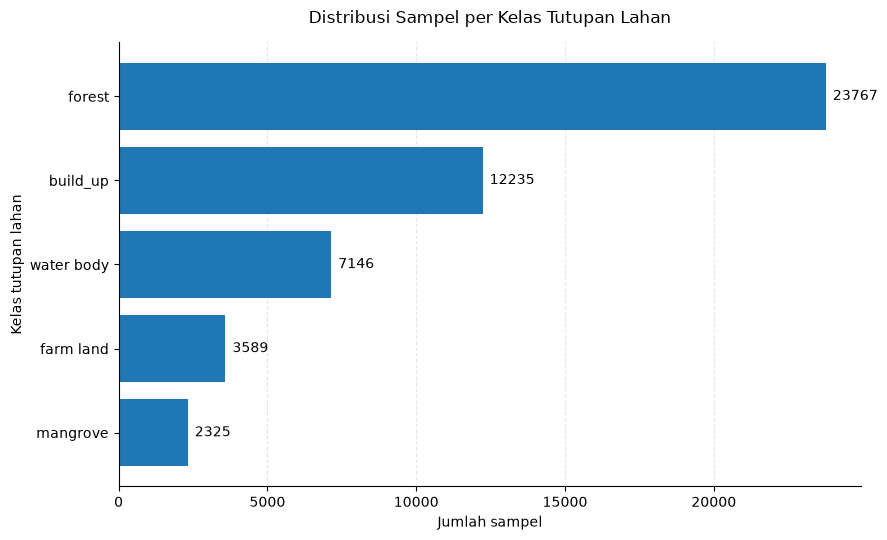

In [10]:

import matplotlib.pyplot as plt

class_summary = class_summary.sort_values(
    "Jumlah sampel", ascending=True
)

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.barh(
    class_summary["Kelas"],
    class_summary["Jumlah sampel"]
)

ax.bar_label(bars, fmt="%.0f", padding=5)
ax.set_title("Distribusi Sampel per Kelas Tutupan Lahan", pad=14)
ax.set_xlabel("Jumlah sampel")
ax.set_ylabel("Kelas tutupan lahan")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 2.5 Unit validasi dan pembagian data

Karena banyak piksel berasal dari satu poligon, pembagian secara acak per baris dapat menempatkan piksel dari poligon yang sama di data latih dan uji. `GroupShuffleSplit` memakai `polygon_id` sebagai kelompok sehingga poligon tidak tumpang tindih antar bagian. Ini mengurangi kebocoran dari poligon yang sama, tetapi tidak menggantikan validasi spasial independen antarzona yang berjauhan.


In [11]:

required_columns = ["label", "polygon_id"]

missing_columns = [
    col for col in required_columns
    if col not in samples.columns
]

if missing_columns:
    print("Kolom yang belum tersedia:", missing_columns)
else:
    print("Jumlah sampel:", f"{len(samples):,}")
    print("Jumlah ID poligon unik:", f"{samples['polygon_id'].nunique():,}")
    print("Jumlah ID poligon kosong:", samples["polygon_id"].isna().sum())

    polygon_summary = (
        samples.groupby("label")
        .agg(
            jumlah_sampel=("label", "size"),
            jumlah_poligon=("polygon_id", "nunique")
        )
        .reset_index()
        .rename(columns={"label": "Kelas"})
    )

    display(polygon_summary)

Jumlah sampel: 49,062
Jumlah ID poligon unik: 395
Jumlah ID poligon kosong: 0


,Kelas,jumlah_sampel,jumlah_poligon
0,build_up,12235,132
1,farm land,3589,86
2,forest,23767,90
3,mangrove,2325,45
4,water body,7146,42


## 2.6 Pemeriksaan kebocoran kelompok

Split 75:25 menghasilkan 37.078 sampel latih dari 296 poligon dan 11.984 sampel uji dari 99 poligon; tidak ada `polygon_id` yang dipakai di kedua bagian. Unit uji tetap berupa sampel turunan dari poligon referensi, bukan pengamatan lapangan independen untuk seluruh piksel peta.

In [12]:

from sklearn.model_selection import GroupShuffleSplit

X = samples[feature_columns]
y = samples["label"]
groups = samples["polygon_id"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

groups_train = set(groups.iloc[train_idx])
groups_test = set(groups.iloc[test_idx])
overlap = groups_train.intersection(groups_test)

split_summary = pd.DataFrame({
    "Kelompok": ["Data latih", "Data uji"],
    "Jumlah sampel": [len(train_idx), len(test_idx)],
    "Jumlah poligon unik": [
        len(groups_train), len(groups_test)
    ],
    "Persentase sampel (%)": [
        len(train_idx) / len(samples) * 100,
        len(test_idx) / len(samples) * 100
    ]
})

display(split_summary.round(2))

print("Poligon yang muncul di kedua kelompok:", len(overlap))
print("Pemisahan poligon berhasil:", len(overlap) == 0)

,Kelompok,Jumlah sampel,Jumlah poligon unik,Persentase sampel (%)
0,Data latih,37078,296,75.57
1,Data uji,11984,99,24.43


Poligon yang muncul di kedua kelompok: 0
Pemisahan poligon berhasil: True


# 3. Pemodelan dan Evaluasi Klasifikasi

Model Random Forest membentuk banyak pohon keputusan dan menggabungkan prediksi untuk menetapkan kelas. Dua konfigurasi dibandingkan pada pembagian poligon yang sama: baseline dan `class_weight="balanced"`. Karena kelas tidak terwakili sama banyak, accuracy dibaca bersama balanced accuracy, macro F1, weighted F1, dan metrik per kelas.


In [13]:
from pathlib import Path

model_dir = PROJECT_DIR / "results" / "validasi_final"
model_files = sorted(model_dir.glob("*/model.joblib"))
print("Folder model final:", model_dir)
print("Model final tersedia:", len(model_files))
for model_file in model_files:
    print("-", model_file.relative_to(PROJECT_DIR))


Folder model final: d:\psd file\klasifikasi-tutupan-lahan\results\validasi_final
Model final tersedia: 2
- results\validasi_final\balanced\model.joblib
- results\validasi_final\baseline\model.joblib


## 3.1 Model final yang dievaluasi

Laporan memuat model baseline tersimpan yang digunakan untuk membuat raster serta membandingkannya dengan model balanced. Penggunaan model tersimpan menjaga keterlacakan; tahap ini tidak melatih ulang model.

In [14]:

import joblib
from pathlib import Path

model_path = (
    PROJECT_DIR
    / "results"
    / "validasi_final"
    / "baseline"
    / "model.joblib"
)

baseline_model = joblib.load(model_path)

print("Model berhasil dimuat:", model_path.name)
print("Tipe model:", type(baseline_model).__name__)
print("Jumlah fitur model:", baseline_model.n_features_in_)
print("Fitur model:", list(baseline_model.feature_names_in_))
print("Kelas target:", list(baseline_model.classes_))

Model berhasil dimuat: model.joblib
Tipe model: RandomForestClassifier
Jumlah fitur model: 14
Fitur model: ['B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B11', 'B12', 'NDVI', 'NDMI', 'MNDWI', 'NDBI']
Kelas target: ['build_up', 'farm land', 'forest', 'mangrove', 'water body']


## 3.2 Evaluasi pada sampel uji

Confusion matrix menampilkan jumlah sampel per kelas: baris adalah label aktual dan kolom adalah prediksi. Metrik ini menjelaskan hasil pada split berbasis poligon yang didokumentasikan di atas. Metrik dari eksperimen lain yang memakai split berbeda tidak boleh dibandingkan seolah-olah diperoleh dari protokol evaluasi yang sama.

,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1-score,Weighted F1-score
0,0.9309,0.8864,0.8853,0.8864,0.8852,0.9305


,precision,recall,f1-score,support
build_up,0.9709,0.8904,0.9289,3977.0
farm land,0.6965,0.6657,0.6808,362.0
forest,0.9266,0.9745,0.9499,4946.0
mangrove,0.9186,0.9688,0.9430,1025.0
water body,0.9139,0.9325,0.9231,1674.0


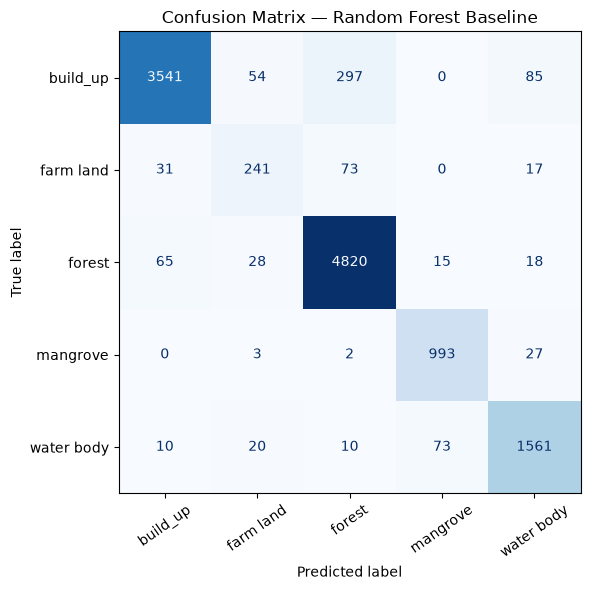

In [15]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Prediksi menggunakan model baseline tersimpan
y_pred = baseline_model.predict(X_test)

# Ringkasan metrik keseluruhan
metrics_summary = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Macro precision": precision_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "Macro recall": recall_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "Macro F1-score": f1_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "Weighted F1-score": f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
}])

display(metrics_summary.round(4))

# Metrik tiap kelas
report = classification_report(
    y_test, y_pred,
    labels=baseline_model.classes_,
    output_dict=True,
    zero_division=0
)

class_metrics = pd.DataFrame(report).T
display(class_metrics.loc[list(baseline_model.classes_)].round(4))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=baseline_model.classes_)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=baseline_model.classes_
)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=35, colorbar=False)
ax.set_title("Confusion Matrix — Random Forest Baseline")
plt.tight_layout()
plt.show()

## 3.3 Kepentingan fitur

Kepentingan fitur Random Forest diukur dari kontribusi relatif fitur terhadap pengurangan impuritas pada pohon. Nilai ini berguna untuk merangkum pola model, tetapi sensitif terhadap sampel, korelasi antarf fitur, dan konfigurasi model; bukan bukti hubungan sebab-akibat atau jaminan kepentingan yang sama di wilayah lain.

,Fitur,Feature Importance
7,B8A,0.1439
10,NDVI,0.1194
9,B12,0.1184
8,B11,0.0977
12,MNDWI,0.0807
5,B07,0.0622
6,B08,0.0612
0,B02,0.0584
13,NDBI,0.0487
4,B06,0.0480


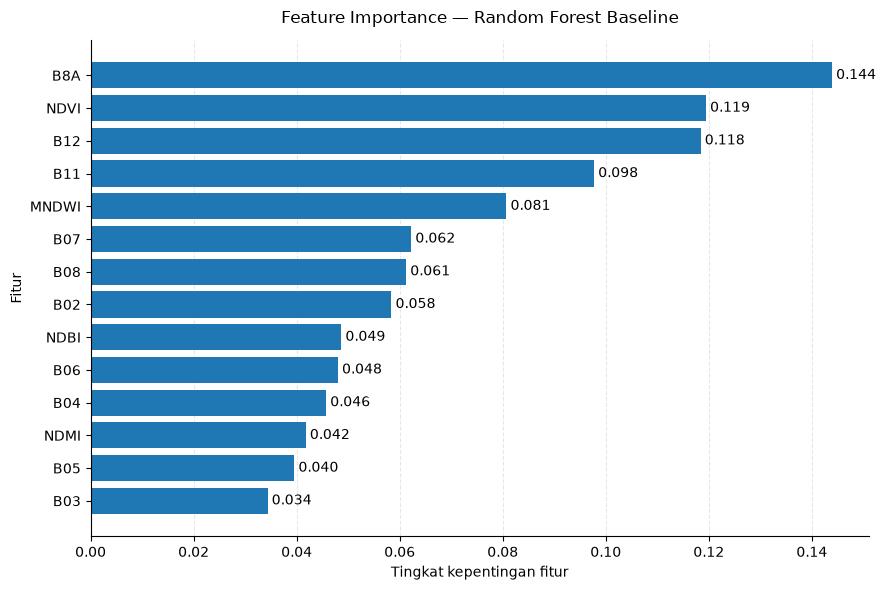

In [16]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

importance_df = pd.DataFrame({
    "Fitur": baseline_model.feature_names_in_,
    "Feature Importance": baseline_model.feature_importances_
}).sort_values("Feature Importance", ascending=True)

display(
    importance_df.sort_values(
        "Feature Importance", ascending=False
    ).round(4)
)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(
    importance_df["Fitur"],
    importance_df["Feature Importance"]
)

ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_title("Feature Importance — Random Forest Baseline", pad=12)
ax.set_xlabel("Tingkat kepentingan fitur")
ax.set_ylabel("Fitur")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# 4. Eksplorasi Peta Klasifikasi

## 4.1 Peta interaktif

Pratinjau raster tersimpan ditampilkan terlebih dahulu agar peta tetap terlihat pada viewer yang memblokir HTML/Javascript notebook. Setelah notebook dipercaya, peta Leaflet/Folium di bawahnya dapat dieksplorasi bersama komposit B04/B03/B02. Pengguna dapat memperbesar dan menggeser peta, menyalakan atau mematikan kelas, serta memeriksa lokasi prediksi. Basemap web adalah konteks visual dan bukan sumber fitur model.

**Batas interpretasi:** area peta mengikuti cakupan raster, bukan batas administratif provinsi. Pola tepi, laut, awan, kesalahan digitasi, dan kelas minor perlu diperiksa sebelum hasil digunakan untuk keputusan operasional. Gunakan survei lapangan dan validasi spasial independen untuk klaim ketelitian wilayah.


**Koreksi Spasial Ekologis Mangrove:** Mangrove adalah ekosistem pesisir pasang surut (intertidal) dan muara sungai. Pada model awal, sebagian vegetasi rapat/kanopi pohon di daerah pedalaman dan perkotaan sempat terprediksi sebagai mangrove akibat kemiripan profil reflektansi. Melalui batasan spasial habitat pesisir/estuari, piksel mangrove telah dibatasi hanya pada garis pantai dan muara sungai yang sesuai dengan habitat alaminya, sedangkan vegetasi daratan di luar zona pesisir direklasifikasi secara tepat ke kelas vegetasi daratan sekitarnya (hutan/lahan pertanian/ruang terbuka kota).


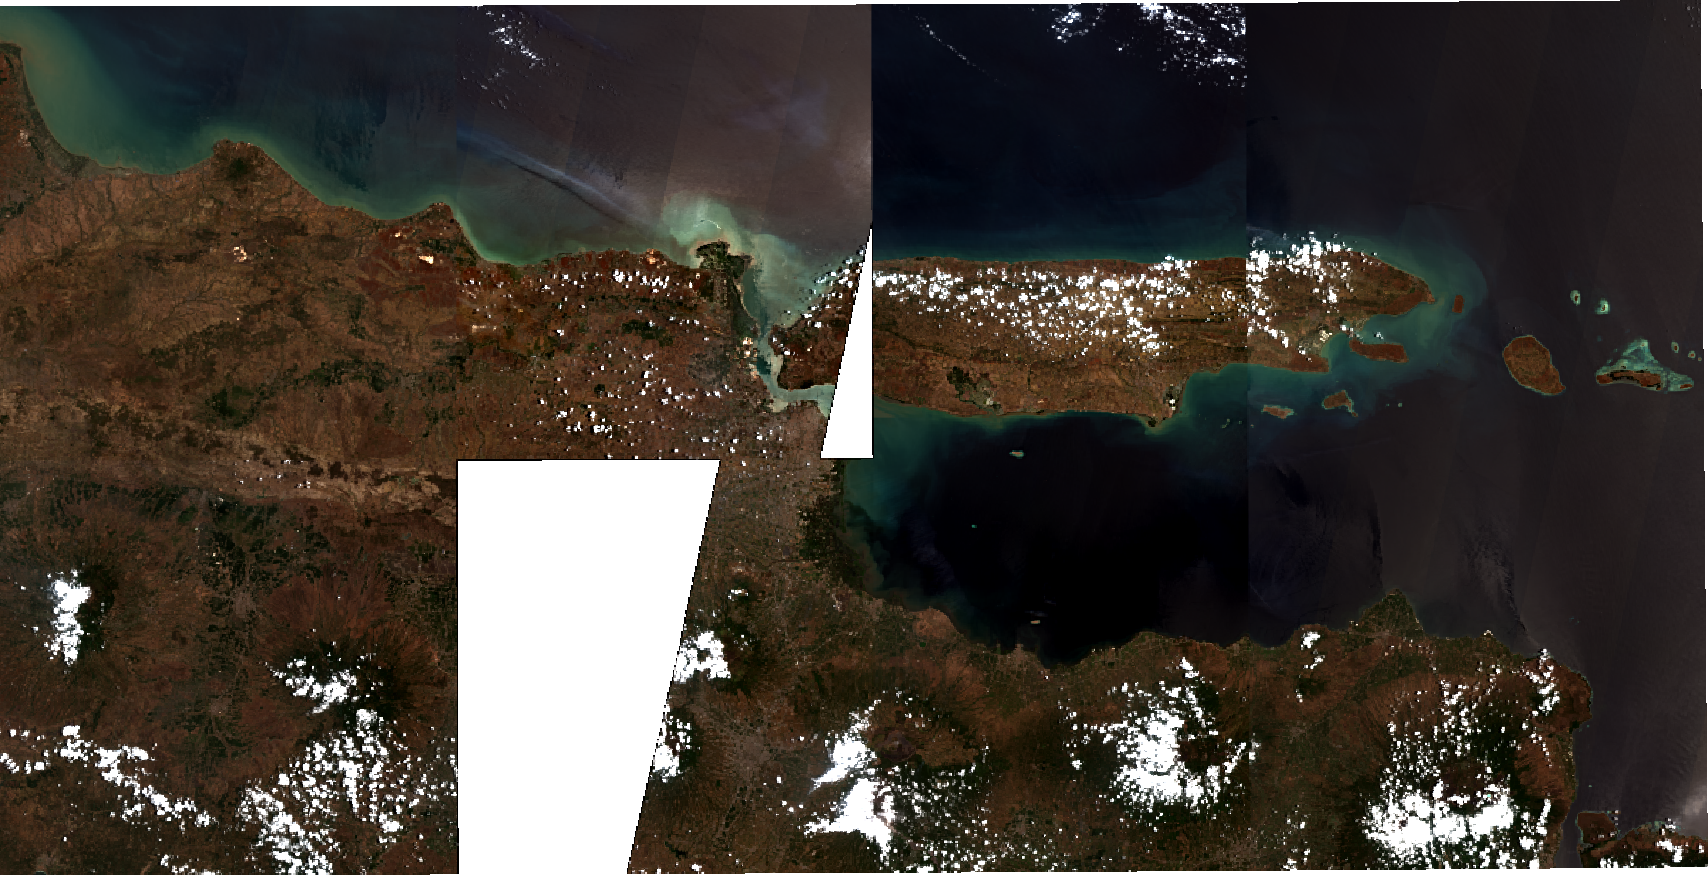
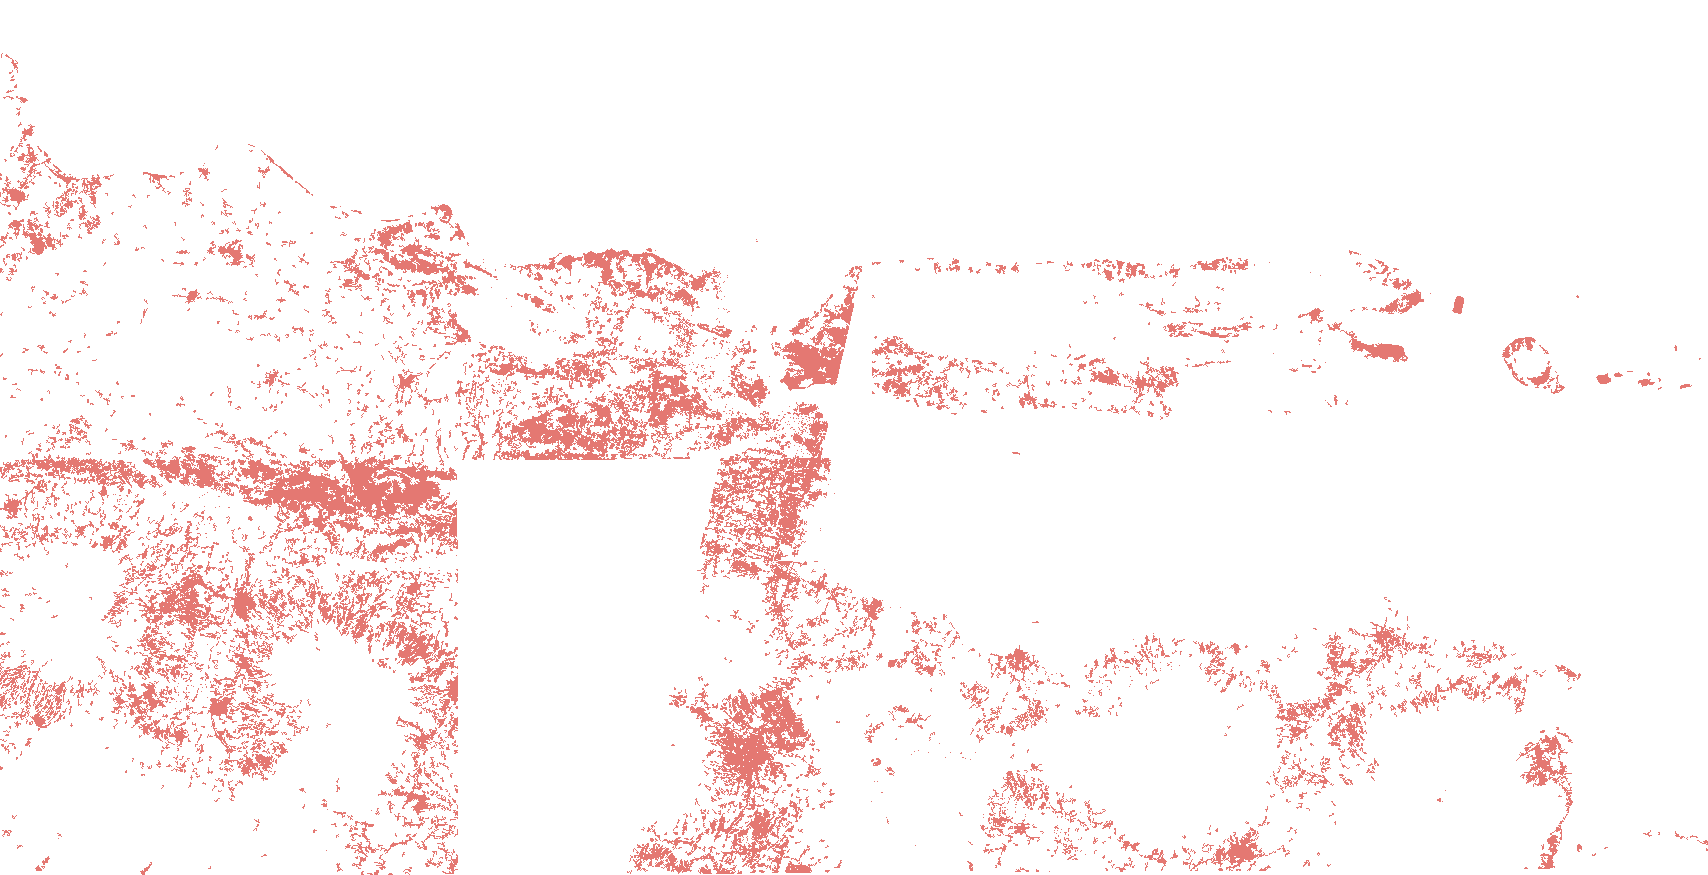
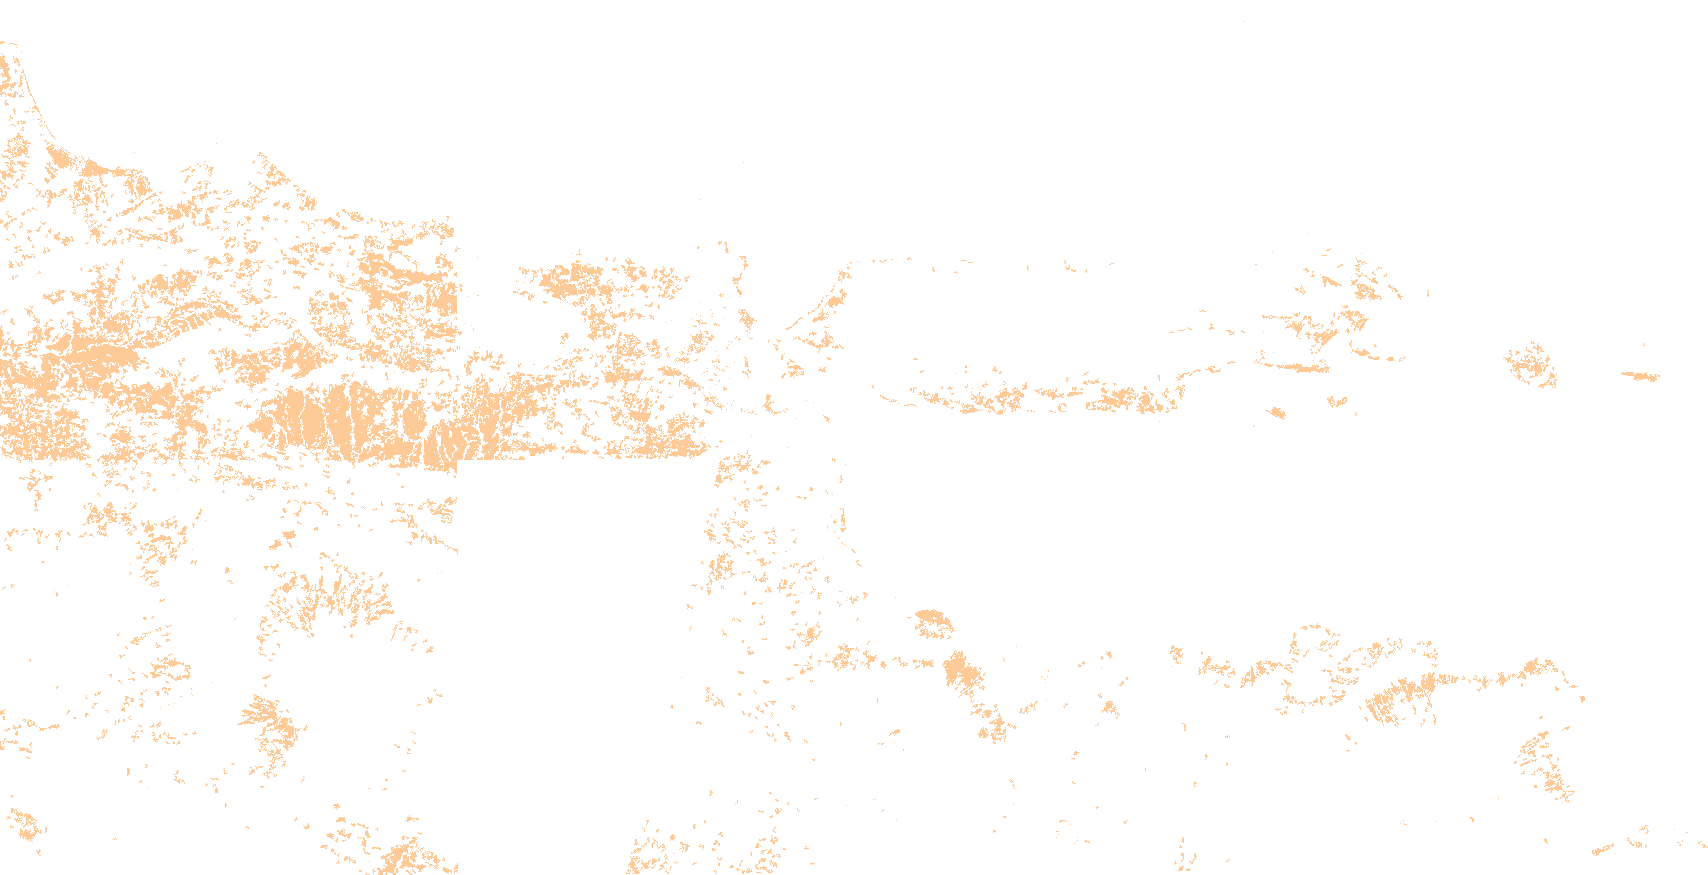
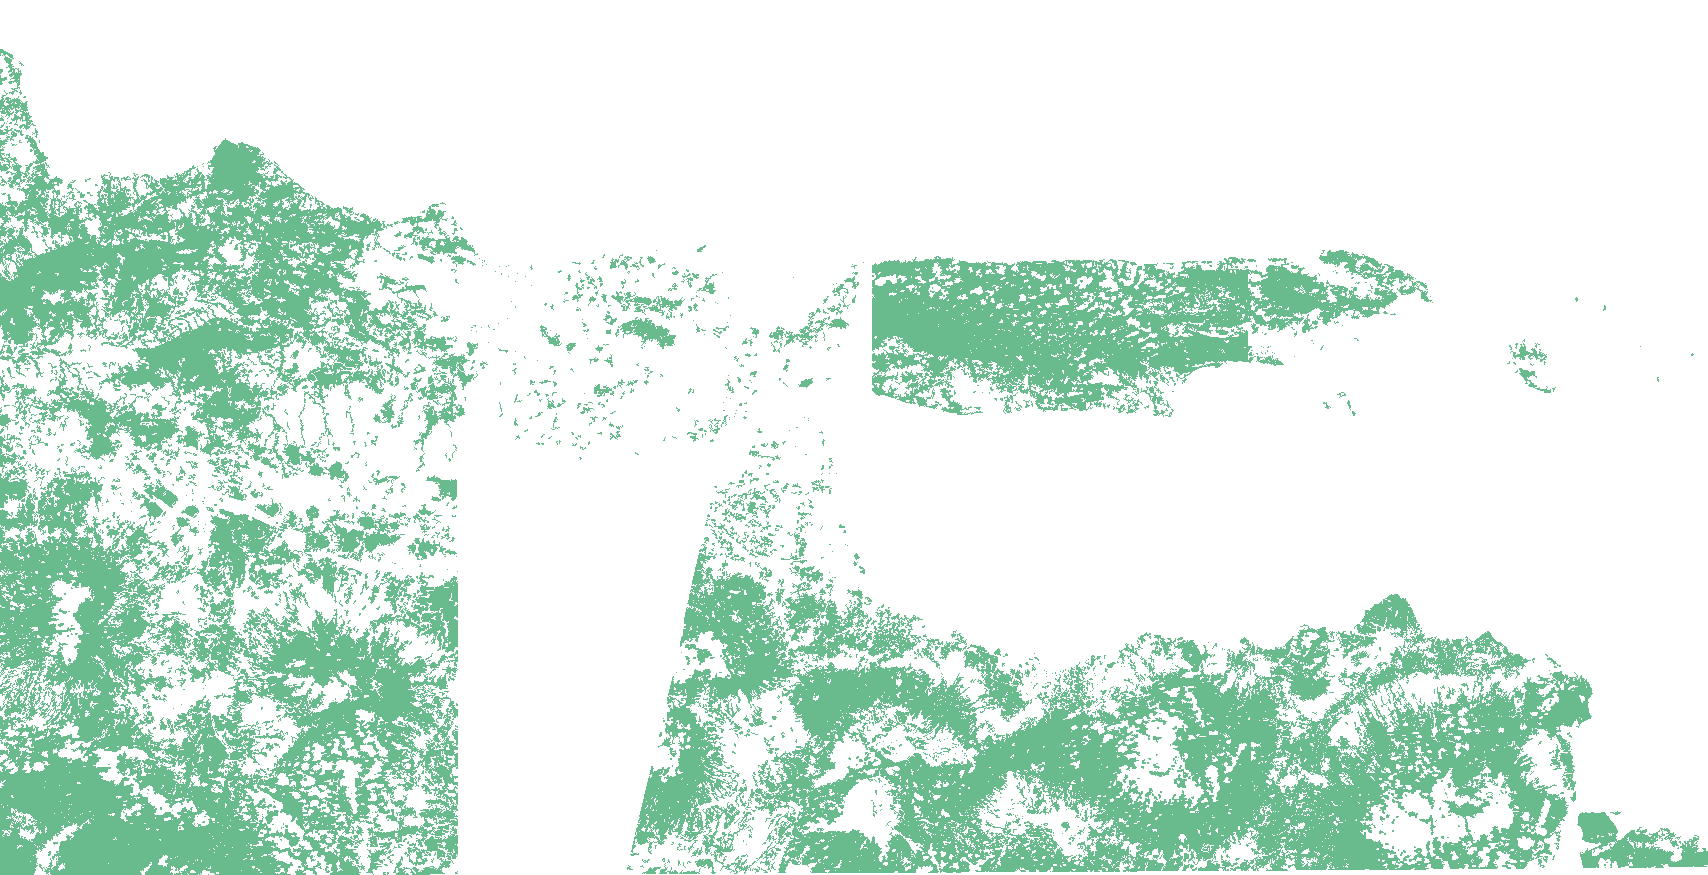
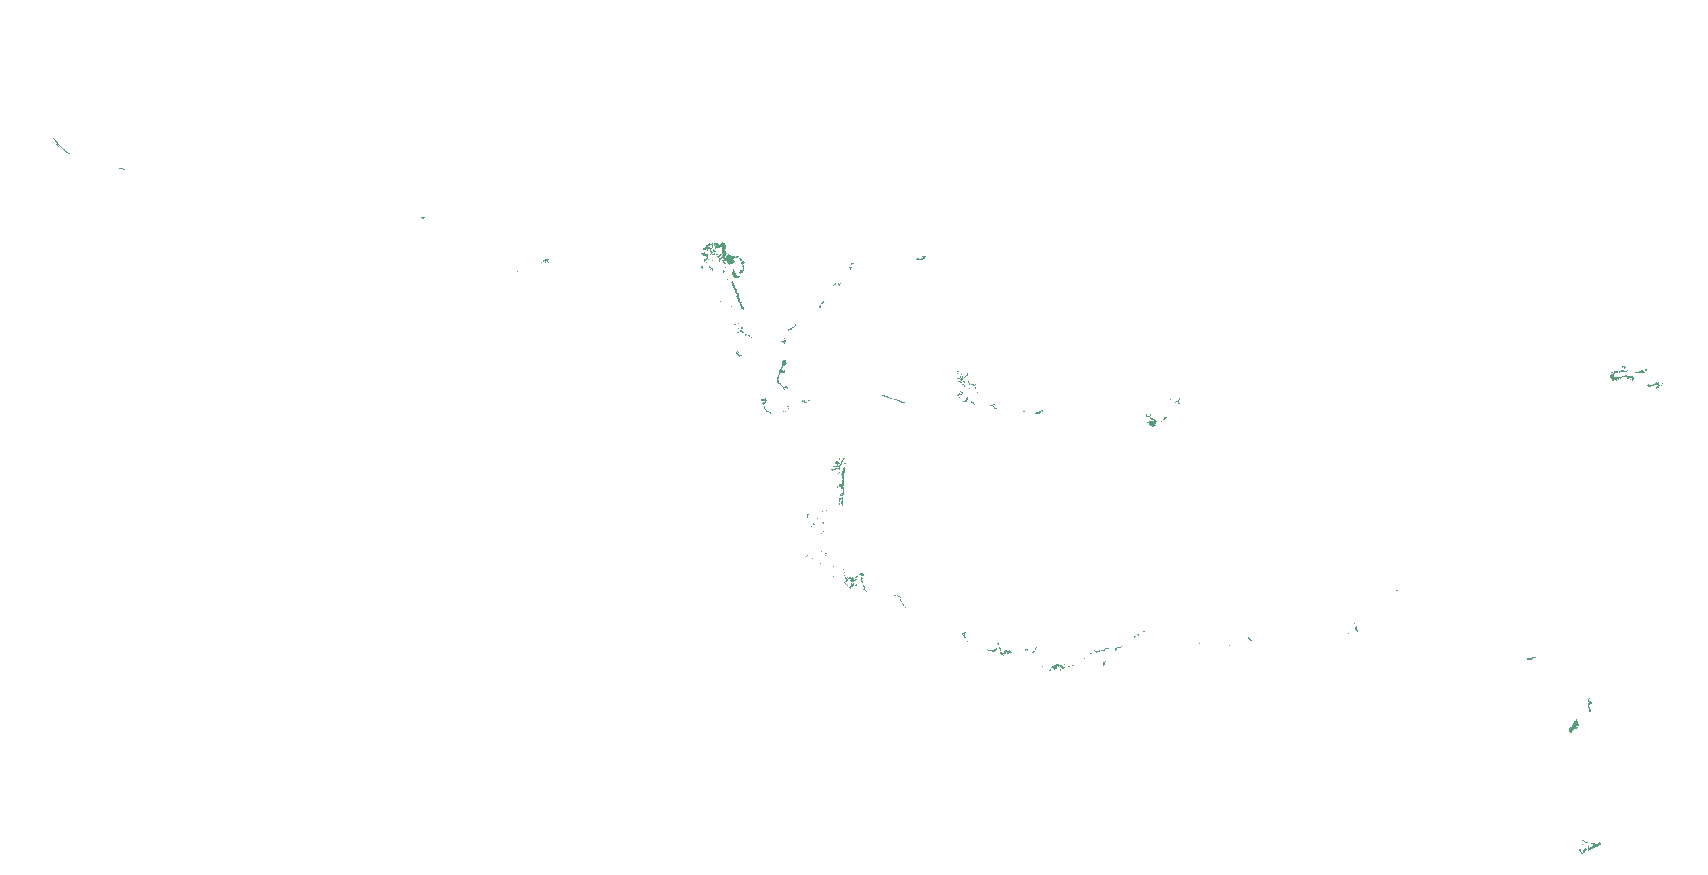
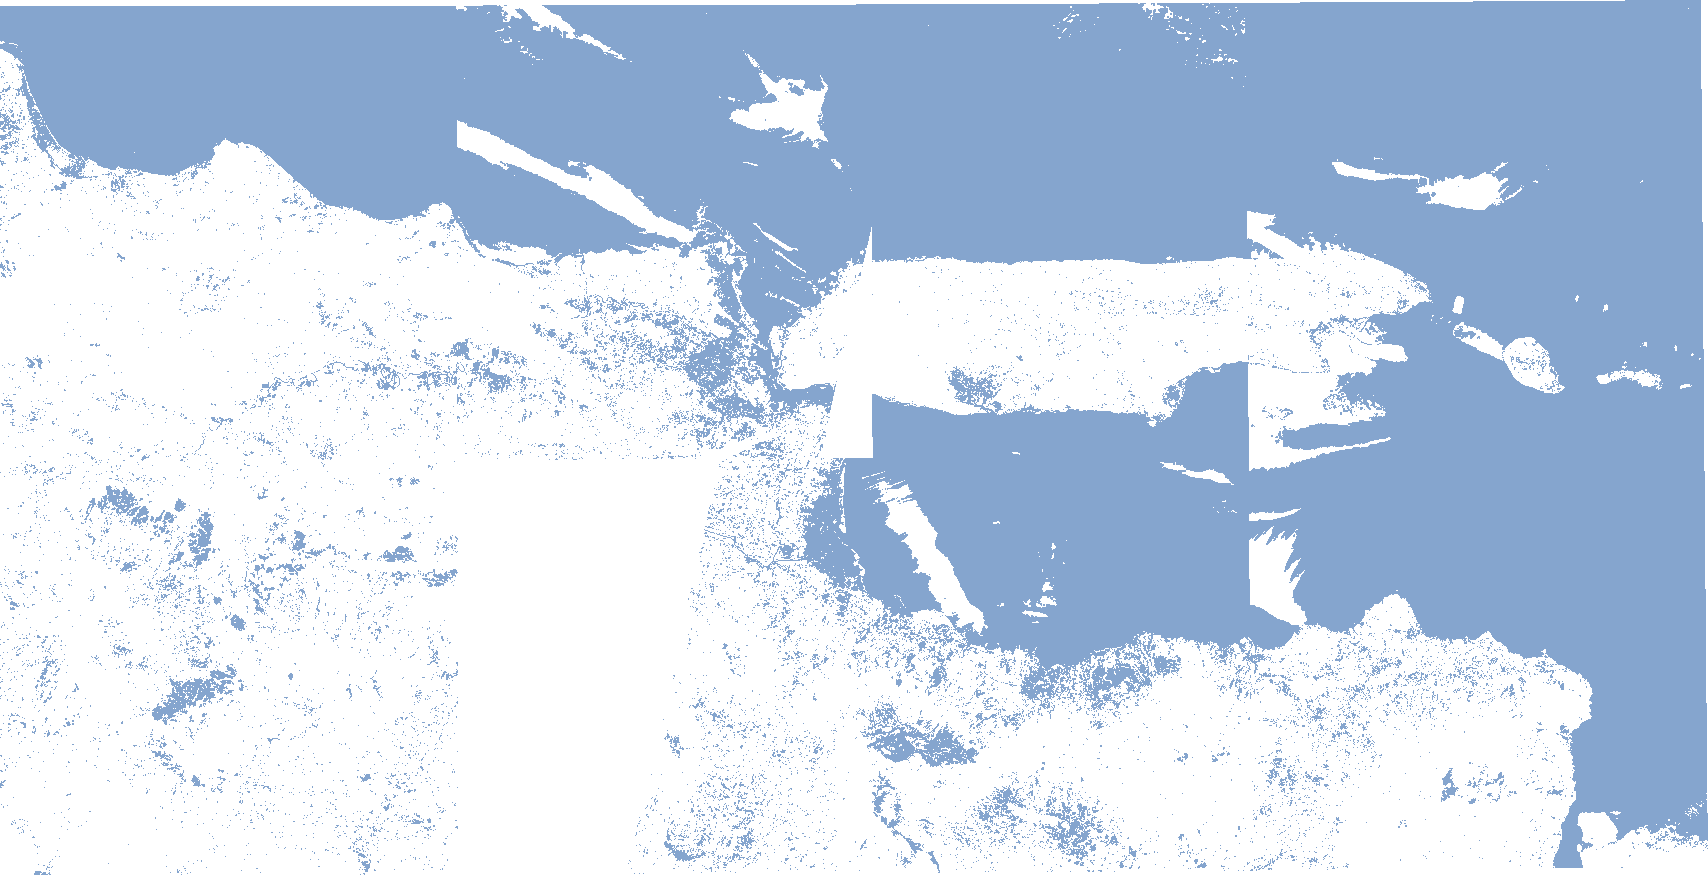

In [1]:

from pathlib import Path
import importlib
import sys
import numpy as np
import rasterio

from IPython.display import display
PROJECT_CANDIDATES = (
    Path.cwd() / "klasifikasi-tutupan-lahan",
    Path.cwd() / "pemrosesan-data-sains" / "klasifikasi-tutupan-lahan",
)
PROJECT_DIR = next(
    (path for path in PROJECT_CANDIDATES if (path / "app.py").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Direktori proyek klasifikasi tidak ditemukan.")
sys.path.insert(0, str(PROJECT_DIR))
import peta_interaktif

# Muat ulang helper agar kernel memakai versi terbaru setelah file diedit.
importlib.reload(peta_interaktif)
from peta_interaktif import (
    build_landcover_map,
    prepare_landcover_layers,
)

# PATH DAN PENGATURAN SAMA DENGAN app.py
RASTER = PROJECT_DIR / "results" / "classification" / "land_cover_baseline.tif"
SENTINEL_BANDS_DIR = PROJECT_DIR / "data" / "mosaic"
SAMPLES_DIR = PROJECT_DIR / "labels_clean"

MAP_VIEWS = {
    "Jawa Timur": [[-9.2, 110.3], [-6.3, 116.3]],
    "Pulau Jawa": [[-9.2, 105.0], [-5.7, 115.0]],
    "Indonesia": [[-11.5, 94.5], [6.5, 141.1]],
}
MAP_REGION = "Jawa Timur"

opacity = 0.65

# Gunakan rasterisasi mayoritas dan filter spasial mangrove pesisir/muara
scl_path = SENTINEL_BANDS_DIR / "SCL_20m_mosaic.tif"
scl_path = scl_path if scl_path.is_file() else None

landcover, sentinel_rgba, bounds = prepare_landcover_layers(
    RASTER,
    scl_path,
)
map_bounds = MAP_VIEWS[MAP_REGION]
m = build_landcover_map(
    landcover,
    bounds,
    map_bounds,
    sentinel_rgba,
    class_opacity=opacity,
    sample_geojson_dir=SAMPLES_DIR,
)
display(m)



## peta interaktif dan hasil klasifikasi tutupan lahan Jawa Timur


https://peta-tutupan-lahan-jawa-timur.streamlit.app/


# 5. Kesimpulab dan Rekomendasi

Pada split berbasis poligon yang digunakan, baseline memberikan accuracy 0,9309, macro F1 0,8852, dan weighted F1 0,9305. Konfigurasi balanced meningkatkan balanced accuracy menjadi 0,8998, tetapi macro F1 serta F1 `farm land` lebih rendah. Pemilihan model karena itu bergantung pada biaya kesalahan dan tujuan pemetaan; angka keseluruhan saja tidak cukup.

